In [1]:
from ech_discovery.notebook import *

In [2]:
files = list(sorted((config.PROCESSED_DATA_DIR / "ark").glob("*/*.pq.zst")))
df = pl.scan_parquet(
    files,
    include_file_paths=C.measurement,
).with_columns(
    pl.coalesce(pl.col("^.*inst$")).alias("vp"),
    pl.col(C.measurement)
    .str.split("/")
    .list.get(-2)
    .str.replace_all("_", ":")
    .str.to_datetime("%+"),
)

# Load data

In [3]:
def load_data(file):

    df = (
        pl.read_parquet(
            file,
            include_file_paths=C.measurement,
        )
        .with_columns(
            pl.coalesce(pl.col("^.*inst$")).alias("vp"),
            pl.col(C.measurement)
            .str.split("/")
            .list.get(-2)
            .str.replace_all("_", ":")
            .str.to_datetime("%+"),
            pl.col("ech_hsrtt", "hsrtt")
            .str.to_time()
            .cast(pl.Duration)
            .dt.total_microseconds()
            / 10**3,
            cs.matches("^dns_.*(tx|rx)$").str.to_datetime("%+"),
            (
                cs.matches("^.*(tls|hdr|data).*(tx|rx)$") & cs.list(cs.string())
            ).list.eval(pl.element().str.to_datetime("%+")),
        )
        .with_columns(
            cs.matches("^.*(tls|hdr|data).*(tx|rx)$").cast(
                pl.List(pl.Datetime(time_zone="UTC"))
            )
        )
        .with_columns(
            (
                (
                    (pl.col(f"{col}_rx") - pl.col(f"{col}_tx")).dt.total_microseconds()
                    / 10**3
                ).alias(f"{col}_rtt")
                for col in ["dns_HTTPS_dns", "dns_A_dns"]
            ),
        )
        .with_columns(
            (
                (
                    (
                        pl.col(f"{col}_rx").list.min() - pl.col(f"{col}_tx").list.min()
                    ).dt.total_microseconds()
                    / 10**3
                ).alias(f"{col}_min_rtt")
                for col in [
                    "tls",
                    "hdr",
                    "ech_tls",
                    "ech_hdr",
                    "ech_data",
                    "grease_tls",
                    "grease_hdr",
                    "grease_data",
                ]
            )
        )
        .with_columns(
            # List columns: duration calculation
            (
                (
                    (
                        pl.col(f"{col}_rx").list.max() - pl.col(f"{col}_tx").list.min()
                    ).dt.total_microseconds()
                    / 10**3
                ).alias(f"{col}_max_rtt")
                for col in [
                    "tls",
                    "hdr",
                    "ech_tls",
                    "ech_hdr",
                    "ech_data",
                    "grease_tls",
                    "grease_hdr",
                    "grease_data",
                ]
            )
        )
        .with_columns(
            (pl.col("ech_tls_max_rtt") - pl.col("tls_max_rtt")).alias(
                "ech_minus_tls_rtt"
            )
        )
        .with_columns(
            (pl.col("ech_tls_max_rtt") - pl.col("grease_tls_max_rtt")).alias(
                "ech_minus_grease_tls_rtt"
            )
        )
    )
    return df

df = load_data(files)

# Time distribution

In [4]:
agg = df.filter(
    pl.col("ech_ech_outer_sni").is_in(["cloudflare-ech.com", "graph.facebook.com"]),
).unpivot(
    cs.contains("rtt"),
    index=[C.measurement, "target", "ech_ech_outer_sni", "vp"],
    variable_name="type",
)
agg

measurement,target,ech_ech_outer_sni,vp,type,value
"datetime[μs, UTC]",binary,str,str,str,str
2026-05-23 00:49:49 UTC,"b""www.ukphonebook.com""","""cloudflare-ech.com""","""cld5-us""","""hsrtt""","""18.966"""
2026-05-23 00:49:49 UTC,"b""www.ukphonebook.com""","""cloudflare-ech.com""","""cld6-us""","""hsrtt""","""5.462"""
2026-05-23 00:49:49 UTC,"b""www.ukphonebook.com""","""cloudflare-ech.com""","""las-us""","""hsrtt""","""6.2170000000000005"""
…,…,…,…,…,…
2026-05-29 23:08:18 UTC,"b""detail.ie""","""cloudflare-ech.com""","""bio-es""","""ech_minus_grease_tls_rtt""","""0.5510000000000019"""
2026-05-29 23:08:18 UTC,"b""detail.ie""","""cloudflare-ech.com""","""sjj-ba""","""ech_minus_grease_tls_rtt""","""0.005000000000002558"""


/mnt/data01/artifacts-active-ech/06-ech-analysis/reports/figures/ech-penalty/lin_ark_ech_delay.png


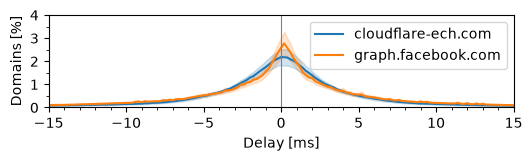

In [5]:
group_by = ["ech_ech_outer_sni", "vp"]
every = "200i"

aggregated = (
    df.filter(
        pl.col("ech_minus_tls_rtt").is_not_null(),
        pl.col("ech_ech_outer_sni").is_not_null(),
    )
    .with_columns((pl.col("ech_minus_tls_rtt") * 1000).cast(pl.Int64))
    .sort(["ech_minus_tls_rtt"] + group_by)
    .group_by_dynamic(
        "ech_minus_tls_rtt",
        every=every,
        group_by=group_by,
    )
    .agg(pl.len())
    .with_columns(
        pl.col("ech_minus_tls_rtt") / 1000,
        (
            pl.col(C.len) / pl.col(C.len).sum().over("vp", "ech_ech_outer_sni") * 100
        ).alias(C.len_percent),
    )
)

fig, ax = vh.fig_ax((6, 1.2))

data = aggregated.filter(
    pl.col("ech_ech_outer_sni").is_in(["cloudflare-ech.com", "graph.facebook.com"]),
    pl.col("ech_minus_tls_rtt") >= -15,
    pl.col("ech_minus_tls_rtt") <= 15,
)

sns.lineplot(
    data,
    x="ech_minus_tls_rtt",
    y=C.len_percent,
    hue="ech_ech_outer_sni",
)
ax.vlines(
    0,
    -1,
    4,
    "grey",
    linewidth=0.8,
)
ax.xaxis.set_minor_locator(ticker.MultipleLocator(1))
ax.yaxis.set_minor_locator(ticker.MultipleLocator(0.5))
ax.yaxis.set_major_locator(ticker.MultipleLocator(1))

ax.legend(title=None)
ax.set(ylim=(0, 4))
ax.set(xlim=(-15,15))
ax.set(ylabel=Strings.latency)
ax.set(xlabel=Strings.delay)
vh.save_plot(
    fig,
    f"lin_ark_ech_delay",
    config.FIGURES_DIR / "ech-penalty",
)